## How to Use EvalXAI Framework for Sentiment Analysis – A Beginner-Friendly Guide 🚀

#### What is EvalXAI?

Imagine you have a sentiment analysis model that predicts whether a sentence is positive, neutral, or negative. But how does it know what makes a sentence negative? Does it focus on the right words?

That’s where EvalXAI helps! 🦊

✅ EvalXAI explains model predictions by showing which words had the most impact.

✅ Helps you trust the model’s decisions.

✅ Useful for debugging why your model makes mistakes.

In [1]:
import sys
sys.path.append('..')
from XAIbenchmark import XAIFramework
import warnings

warnings.filterwarnings("ignore")

d:\TUM courses\thesis- nlp\EvalXAI\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%load_ext autoreload
%autoreload 2

#### Single Sentence

Step 1: Load a pre-trained Sentiment Model, and Tokenizer

In [3]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Optionally initialize the explainers, and evaluators

In [4]:
from explainers import InputXGradientExplainer, IntegratedGradientsExplainer, DeepLiftExplainer, LimeExplainer, SHAPExplainer, SHAPIQExplainer, GuidedBackpropExplainer

ig= IntegratedGradientsExplainer(model,tokenizer)
gb= GuidedBackpropExplainer(model,tokenizer)
dl= DeepLiftExplainer(model,tokenizer)
ixg= InputXGradientExplainer(model,tokenizer)
lime= LimeExplainer(model,tokenizer)
shap= SHAPExplainer(model,tokenizer)
shapiq= SHAPIQExplainer(model,tokenizer)

In [5]:
from evaluators import AUCTPEvaluator, SoftComprehensivenessEvaluator, SoftSufficiencyEvaluator, FADEvaluator, SparsenessEvaluator, ComplexityEvaluator, IOUEvaluator, AUPRCEvaluator

sc= SoftComprehensivenessEvaluator(model,tokenizer)
ss= SoftSufficiencyEvaluator(model,tokenizer)
fad= FADEvaluator(model,tokenizer)
sp= SparsenessEvaluator(model,tokenizer)
cx= ComplexityEvaluator(model,tokenizer)
auctp= AUCTPEvaluator(model,tokenizer)
iou= IOUEvaluator(model,tokenizer)
auprc= AUPRCEvaluator(model,tokenizer)

Step 3: Inialize XAIBenchmark Class

In [6]:
xai_framework = XAIFramework(model, tokenizer,explainers=[dl], evaluators=[sc])

> **Note:** If you don’t pass any explainers or evaluators, it defaults to all explainers/evaluators.

Step 4: Predict Sentiment of a Sentence

In [72]:
#Define the senece to be explained
sentence = "I love the product, but the customer service was terrible."
# sentence= "You are the sweatest person, I wish I had known you before."
xai_framework.classify_text(sentence)

{'negative': 0.9104563593864441,
 'neutral': 0.05341604724526405,
 'positive': 0.03612753748893738}

Step 5: Use EvalXAI to Explain Why

You can use the `XAIBenchmark` class to explain for all the explainers defined during the initiation of the `XAIBenchmark` class

In [73]:
exps= xai_framework.explain(input_data=sentence,target_label="negative")

Running Inference: 100%|██████████| 25/25 [00:10<00:00,  2.41it/s]


Or you can use an individual explainer's `compute_feature_importance` method to get importance scores.

In [55]:
ig_exps= ig.compute_feature_importance(sentence, target="negative")
gb_exps= gb.compute_feature_importance(sentence, target="negative")
dl_exps= dl.compute_feature_importance(sentence, target="negative")
ixg_exps= ixg.compute_feature_importance(sentence, target="negative")
lime_exps= lime.compute_feature_importance(sentence, target="negative")
shap_exps= shap.compute_feature_importance(sentence, target="negative")
shapiq_exps= shapiq.compute_feature_importance(sentence, target="negative")

print("IG: ",ig_exps)
print("GB: ",gb_exps)
print("DL: ",dl_exps)
print("IXG: ",ixg_exps)
print("LIME: ",lime_exps)
print("SHAP: ",shap_exps)
print("SHAPIQ: ",shapiq_exps)

Running Inference: 100%|██████████| 25/25 [00:10<00:00,  2.43it/s]


IG:  Explanation(text=['I love the product, but the customer service was terrible.'], tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'], scores=array([ 1.73210140e-08, -7.42845348e-09, -2.03939271e-09, -5.76055690e-08,
        2.68824150e-08, -1.60572988e-08, -3.40097237e-08,  7.06896895e-08,
       -1.21586861e-08, -1.31738320e-08, -4.00839713e-08, -7.29788956e-08,
        2.18948555e-08, -2.27215913e-07]), explainer='integratedgradient', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None)
GB:  Explanation(text=['I love the product, but the customer service was terrible.'], tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'], scores=array([-4.0978193e-08,  9.3132257e-09, -9.3132257e-09, -1.9557774e-08,
        7.4505806e-09,  0.0000000e+00,  5.9604645e-08,  3.7252903e-08,
        6.3

In [77]:
print("IG: ",ig_exps)

IG:  Explanation(text=['I love the product, but the customer service was terrible.'], tokens=['<s>', '▁I', '▁love', '▁the', '▁product', ',', '▁but', '▁the', '▁customer', '▁service', '▁was', '▁terrible', '.', '</s>'], scores=array([ 1.73210140e-08, -7.42845348e-09, -2.03939271e-09, -5.76055690e-08,
        2.68824150e-08, -1.60572988e-08, -3.40097237e-08,  7.06896895e-08,
       -1.21586861e-08, -1.31738320e-08, -4.00839713e-08, -7.29788956e-08,
        2.18948555e-08, -2.27215913e-07]), explainer='integratedgradient', target_pos_idx=0, target_token_pos_idx=None, target='negative', target_token=None, rationale=None)


Step 5: Visualize the Explanation

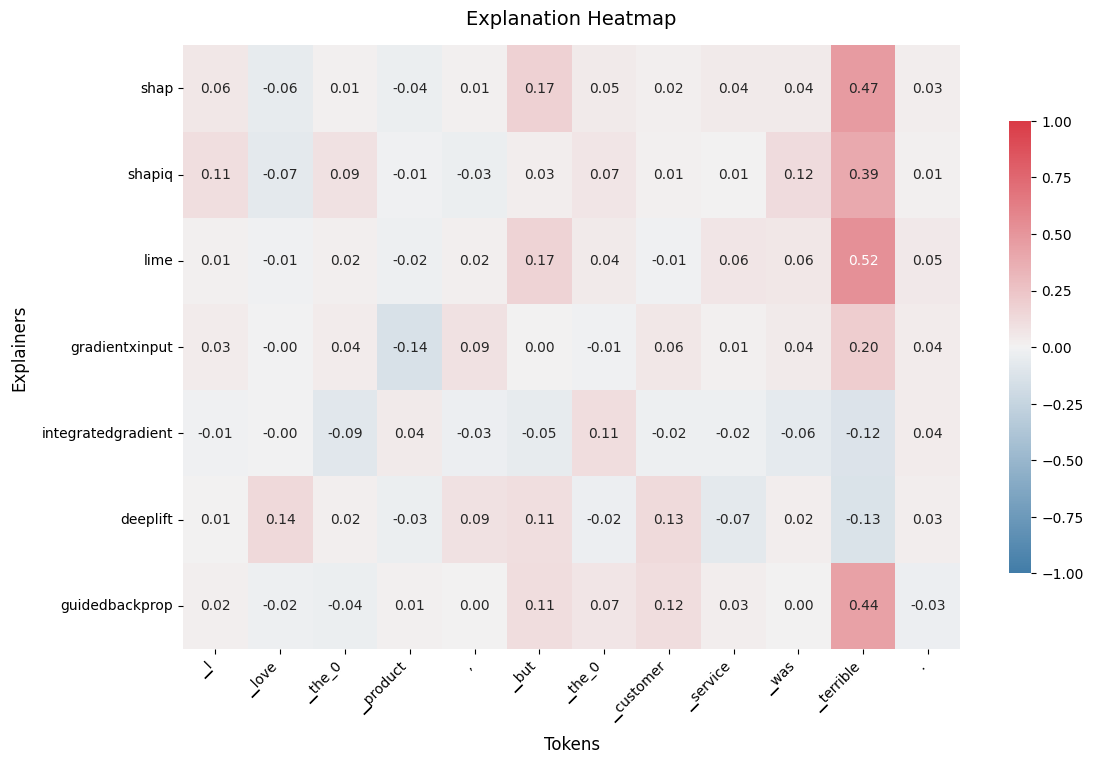

In [74]:
xai_framework.visualize(exps)

📌 How to Interpret EvalXAI's Results?

This heatmap shows how different explanation methods (feature attribution techniques) assign importance scores to different words (tokens) in a sentence.

Each row represents a different explanation method, and each column represents a token (word or punctuation) from the input sentence.

🔴 Red (Positive Score) → Word contributes positively to the prediction.

🔵 Blue (Negative Score) → Word contributes negatively to the prediction.

⚪ White/Neutral (Close to 0) → Word has little to no effect on the prediction.



🧐 What Can We Learn from This?

✔️ Debugging Sentiment Models – If a model misclassifies a sentence, check which words influenced the decision.

✔️ Bias Detection – If neutral words like "customer" heavily influence sentiment, the model may have biases.

✔️ Choosing the Best Explanation Method – Compare different methods and select the most consistent one.

✔️ Improving Model Interpretability – Use this visualization to explain AI decisions to non-technical stakeholders.



Step 5: Evaluate the explanations

You can evaluate explanations from different explainers initialized during the creation of the `XAIBenchmark` class using the `evaluate_single_sentence` function.

- If you provide a **human rationale**, **plausibility metrics** will be calculated.  
- If no rationale is provided, plausibility metrics **will not** be included.  

In [76]:
xai_framework.evaluate_single_sentence(sentence, target_label="negative")

explainer shap
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer shapiq
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer lime


Running Inference: 100%|██████████| 25/25 [00:11<00:00,  2.17it/s]


Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer gradientxinput
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer integratedgradient
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer deeplift
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.
explainer guidedbackprop
Skipping Intersection Over Union (IOU) as human rationale is not provided.
Skipping Area under PR Curve as human rationale is not provided.


Evaluator,Area under TP Curve,Feature Ablation Drop,Soft Comprehensiveness,Sparseness
Explainer,,,,
deeplift,10.0,1.00,0.563739,0.248963
gradientxinput,5.0,0.50,0.563741,0.363656
guidedbackprop,5.0,0.25,0.437284,0.466892
integratedgradient,10.0,0.75,0.563742,0.394562
lime,5.0,0.25,0.501119,0.526336
shap,5.0,0.25,0.422696,0.491863
shapiq,5.0,0.25,0.584407,0.373831


Alternatively, you can use each evaluator’s `compute` function to assess individual metrics.  
For **plausibility metrics**, make sure to **add a rationale** to the explanation object before evaluation.

In [13]:
ig_exps.rationale= [0, 1, 0, 1, 0,0,0,0,1,0,1,0]
iou.compute(ig_exps)
auprc.compute(ig_exps)

np.float64(0.33766233766233766)

#### Dataset

Step 1: Load the model and tokenizer

In [7]:
from transformers import AutoModelForSequenceClassification, AutoTokenizer

model_name = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

Step 2: Load the dataset

You can load any text classification dataset using the `load_fields_from_dataset` function, provided you specify the `LoadDatasetArgs` as follows:  
- **`dataset_name`** - The field containing dataset name on huggingface/ "csv", "json", etc for local files
- **`input_text_field`** – The field containing the text data.  
- **`label_field`** – The field containing the class labels.  
- **`rationale_field`** (optional) – The field marking important tokens in the text.
- **`dataset_files`** (optional) - The field containing filepath to a local csv/excel file e.g. ["healthFC_annotated.csv"]

HuggingFace Dataset

In [8]:
from dataset_loaders.dataset_loader import LoadDatasetArgs,load_fields_from_dataset

dataset_args_ = LoadDatasetArgs(
    dataset_name="eraser-benchmark/movie_rationales",
    input_text_field="review",
    label_field="label",
    rationale_field="evidences",
    dataset_split="test",
)

# Load the dataset fields
input_texts, labels, rationales = load_fields_from_dataset(dataset_args_)

Local CSV File Dataset

In [16]:
dataset_args_csv = LoadDatasetArgs(
    dataset_name="csv",
    input_text_field="en_text",
    label_field="label",
    rationale_field="en_explanation",
    dataset_split="train",
    dataset_files=["healthFC_annotated.csv"]
)
# Load the dataset fields
input_texts_csv, labels_csv, rationales_csv = load_fields_from_dataset(dataset_args_csv)

print(input_texts_csv[0])
print(labels_csv[0])
print(rationales_csv[0])

Generating train split: 750 examples [00:00, 1906.88 examples/s]

This post is part of our fact check series Myths and Facts about Coronavirus In parts of Asia, it was common before the Corona pandemic: the wearing of masks in everyday life. The barrier in the face is meant to prevent contagious diseases from spreading. Through the pandemic, masks are also familiar to the people of Europe.  Background is that Corona infected people emit virus-containing droplets during coughing, sneezing or speaking. The exhaled air of infected people also contains a mist of the finest saliva (aerosols) in which the virus sits. If another person breathes the droplets in sufficient quantities, it can become infected with the corona virus. The problem is that infected people don't know at first that they've been infected. Some people also infect themselves completely symptomless – so they don't get any symptoms at all. However, even if they are not (yet) ill, they can pass on the SARS-CoV-2 virus to others.  At first controversial At the beginning of the pandemic, rese

In [9]:
print(input_texts[0])
print(labels[0])
print(rationales[0])

there may not be a critic alive who harbors as much affection for shlock monster movies as i do .
i delighted in the sneaky - smart entertainment of ron underwood 's big - underground - worm yarn tremors ; i even giggled at last year 's critically - savaged big - underwater - snake yarn anaconda .
something about these films causes me to lower my inhibitions and return to the saturday afternoons of my youth , spent in the company of ghidrah , the creature from the black lagoon and the blob .
deep rising , a big - undersea - serpent yarn , does n't quite pass the test .
sure enough , all the modern monster movie ingredients are in place : a conspicuously multi - ethnic / multi - national collection of bait .
.. excuse me , characters ; an isolated location , here a derelict cruise ship in the south china sea ; some comic relief ; a few cgi - enhanced gross - outs ; and at least one big explosion .
there are too - cheesy - to - be - accidental elements , like a sleazy shipping magnate ( 

Expected Outputs:

- **`input_texts`** → An array of strings (text samples).  
- **`labels`** → An array of strings (corresponding class labels).  
- **`rationale`** → An array of binary values (`0` or `1`), indicating which tokens in the text are important.  

*You can preprocess or postprocess the data to ensure it is in the expected format if needed.*

In [9]:
import numpy as np
NONE_RATIONALE = []  
classes= [0,1]
def _get_offset_rationale(text, text_rationales,tokenizer):
        rationale_offsets = []
        for text_rationale in text_rationales:
            start_i = text.index(text_rationale)
            end_i = start_i + len(text_rationale)
            rationale_encoded_text = tokenizer.encode_plus(
                text[start_i:end_i],
                return_offsets_mapping=True,
                return_attention_mask=False,
            )
            rationale_token_offset = [
                (s + start_i, e + start_i)
                for (s, e) in rationale_encoded_text["offset_mapping"]
                if (s == 0 and e == 0) == False
            ]
            rationale_offsets.append(rationale_token_offset)
        return rationale_offsets

def _get_rationale_one_hot_encoding(offsets, rationale_offsets, len_tokens):
        rationale = np.zeros(len_tokens)

        for rationale_offset in rationale_offsets:
            if rationale_offset in offsets:
                rationale[offsets.index(rationale_offset)] = 1
                # Test what this function is returning
        return rationale


def _get_rationale(text, label, rationales_array, tokenizer, split_type: str = 'test', rationale_union=True):
        
        encoded_text = tokenizer.encode_plus(
            text, return_offsets_mapping=True, return_attention_mask=False
        )
        tokens = tokenizer.convert_ids_to_tokens(encoded_text["input_ids"])
        offsets = encoded_text["offset_mapping"]

        # Movie rationales are defined for the ground truth label
        rationale_label = label

        rationale_by_label = [NONE_RATIONALE for c in classes]

        text_rationales = rationales_array
        rationale_offsets = _get_offset_rationale(text, text_rationales,tokenizer)
        if len(text_rationales) > 0 and isinstance(text_rationales, list):
            # It is a list of lists
            if rationale_union:
                # We get the union of the rationales.
                rationale_offsets = [t1 for t in rationale_offsets for t1 in t]
                rationale_by_label[
                    rationale_label
                ] = _get_rationale_one_hot_encoding(
                    offsets, rationale_offsets, len(tokens)
                ).astype(
                    int
                )

            else:
                return rationale_by_label
        else:

            rationale_by_label[
                rationale_label
            ] = _get_rationale_one_hot_encoding(
                offsets, rationale_offsets, len(tokens)
            ).astype(
                int
                )
         # Here we ensure the output is a single 1D array
        if rationale_union:
            # If rationale_union is True, return the single unified rationale as a 1D array
            # Filter out empty lists before using zip
            non_empty_rationale_by_label = [r for r in rationale_by_label if len(r)>0]  # Remove empty lists
            if non_empty_rationale_by_label:
                final_rationale = [int(any(each)) for each in zip(*non_empty_rationale_by_label)]  # Union of all rationales
            else:
                final_rationale = []  # If no valid rationale exists, return an empty list
            return final_rationale
        else:
            # Otherwise, return the rationale for the specific label (may be a list of lists if rationale_union is False)
            return rationale_by_label

In [10]:
texts = [text.replace("\n", " ") for text in input_texts]
rationale_arr= [rationale.tolist() for rationale in rationales] 
processed_rationales = [
    _get_rationale(text, label, rationale, tokenizer) 
    for text, label, rationale in zip(texts, labels, rationale_arr)
]

Select a sub-sample of the dataset

In [12]:
#Select a sub-sample if you want
input_texts_sample=input_texts[100:120]
labels_sample=labels[100:120]
rationale_sample= processed_rationales[100:120]

In [13]:
len(input_texts_sample)

20

Step 3: Generate Explanations

In [14]:
exp_scores= xai_framework.get_feature_importance_for_dataset(input_texts_sample,labels_sample,rationale_sample)
exp_scores

Processing instance 0
Found cached explanation for deeplift
Processing instance 1
Found cached explanation for deeplift
Processing instance 2
Found cached explanation for deeplift
Processing instance 3
Found cached explanation for deeplift
Processing instance 4
Found cached explanation for deeplift
Processing instance 5
Found cached explanation for deeplift
Processing instance 6
Found cached explanation for deeplift
Processing instance 7
Found cached explanation for deeplift
Processing instance 8
Found cached explanation for deeplift
Processing instance 9
Found cached explanation for deeplift
Processing instance 10
Computing explanation for deeplift
Processing instance 11
Computing explanation for deeplift
Processing instance 12
Computing explanation for deeplift
Processing instance 13
Computing explanation for deeplift
Processing instance 14
Computing explanation for deeplift
Processing instance 15
Computing explanation for deeplift
Processing instance 16
Computing explanation for dee

{'deeplift': [Explanation(text=["in 1912 , a ship set sail on her maiden voyage across the atlantic for america .\nthis ship was built to be the largest ship in the world , and she was .\nshe was also build to be one of the most luxurious , and that she was .\nfinally , she was built to be unsinkable and that unfortunately she was not .\nto get a ticket for this voyage\nyou either : spent a life 's savings to get to america to start life anew , were part of the upper class and had the money to spare , or finally were lucky enough to have a full house in a poker match by the docks like jack dawson .\njack dawson makes the trip , and happens to be at the right place at the right time .\nrose dewitt bukater , a first class passenger , climbs the railings at the aft of the ship with thoughts of jumping .\nthus is started a tale of romance and intrigue , and a tale of death and tragedy .\n.. this movie is about a tragic event that took place a great many years ago , an even that should not 

Step 4: Evaluate Explanations and generate table 

In [15]:
metrics= xai_framework.compute_evaluation_metrics(exp_scores)
xai_framework.create_pivot_table(metrics)


Explainer: deeplift
Computing value for Soft Comprehensiveness


Evaluator,Soft Comprehensiveness
Explainer,
deeplift,0.079842


You can also do `Step 3` and `Step 4` together within a single function call.

In [17]:
xai_framework.benchmark_dataset(input_texts_sample, labels_sample,rationales=rationale_sample)

Processing instance 0
Found cached explanation for guidedbackprop
Found cached explanation for deeplift

Explainer: guidedbackprop
Computing value for Area under PR Curve
Computing value for Area under TP Curve
Computing value for Soft Comprehensiveness
Computing value for Feature Ablation Drop
Computing value for Sparseness
Computing value for Complexity
Computing value for Intersection Over Union (IOU)

Explainer: deeplift
Computing value for Area under PR Curve
Computing value for Area under TP Curve
Computing value for Soft Comprehensiveness
Computing value for Feature Ablation Drop
Computing value for Sparseness
Computing value for Complexity
Computing value for Intersection Over Union (IOU)


Evaluator,Area under PR Curve,Area under TP Curve,Complexity,Feature Ablation Drop,Intersection Over Union (IOU),Soft Comprehensiveness,Sparseness
Explainer,,,,,,,
deeplift,0.238352,5.0,0.011412,0.25,0.239216,0.041183,0.478658
guidedbackprop,0.264260,5.0,0.011467,0.25,0.239216,0.041183,0.463317
